# Domestic Flight Price Prediction — 02 · Preprocessing and Feature Engineering

Report sections 4–5: recovering the missing airline and duration values, encoding and scaling, the engineered features, the advanced (leak-free) target statistics, leak tests and an ablation of what each feature idea was worth.

Each step's code is written out in this notebook. The same code lives in `flight_pipeline.py` so that **03_Models** can reuse it; after each step we check that both give identical results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import flight_pipeline as fp

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
BLUE, ORANGE, INK2, MUTED, GRID, BASE = "#2a78d6", "#eb6834", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

## 1. Recovering the airline

The first token of `flight` is the airline's IATA code (`AI 2641` → `AI`). If every prefix maps to exactly one airline, a missing airline is not *imputed* but *recovered* exactly. The mapping uses no price information, so building it on train and test together is not leakage.

In [2]:
def add_prefix(df):
    # 'AI 2641' -> flight_prefix 'AI', flight_number 2641
    df = df.copy()
    parts = df["flight"].str.extract(r"^([A-Za-z0-9]+)[\s-]*(\d*)$")
    df["flight_prefix"] = parts[0]
    df["flight_number"] = pd.to_numeric(parts[1], errors="coerce")
    return df

allx = add_prefix(pd.concat([train.drop(columns="price"), test], ignore_index=True))
known = allx.dropna(subset=["airline"])
purity = known.groupby("flight_prefix")["airline"].nunique()
prefix_map = known.groupby("flight_prefix")["airline"].agg(lambda s: s.mode()[0])
print(f"{len(prefix_map)} prefixes, each mapping to exactly one airline: {bool((purity == 1).all())}")

missing = allx["airline"].isna()
print(f"missing airlines: {missing.sum():,} (train {train['airline'].isna().sum():,}, test {test['airline'].isna().sum():,})")
print(f"recoverable from the prefix: {allx.loc[missing, 'flight_prefix'].isin(prefix_map.index).mean():.0%}")

# check: hide 3,000 known airlines and recover them with a map built without them
rng = np.random.default_rng(0)
hidden = rng.choice(known.index, 3000, replace=False)
pm = known.drop(index=hidden).groupby("flight_prefix")["airline"].agg(lambda s: s.mode()[0])
print(f"accuracy on 3,000 hidden airlines: {(allx.loc[hidden, 'flight_prefix'].map(pm) == allx.loc[hidden, 'airline']).mean():.2%}")

allx["airline"] = allx["airline"].fillna(allx["flight_prefix"].map(prefix_map))

20 prefixes, each mapping to exactly one airline: True
missing airlines: 3,888 (train 3,089, test 799)
recoverable from the prefix: 100%
accuracy on 3,000 hidden airlines: 100.00%


## 2. Imputing the duration

Duration is a property of the **itinerary** (flight number + route + stops + time slots); one flight number can fly several itineraries. Missing values are filled by a cascade of lookups, most specific first, ending with the global median. A flag records which rows were filled.

In [3]:
ITIN = ["flight", "source_city", "destination_city", "stops", "departure_time", "arrival_time"]
DUR_KEYS = [
    ITIN,
    ["flight", "source_city", "destination_city", "stops", "arrival_time"],
    ["flight", "source_city", "destination_city", "stops"],
    ["flight", "stops", "departure_time", "arrival_time"],
    ["flight", "stops"],
    ["flight"],
    ["source_city", "destination_city", "stops", "departure_time", "arrival_time"],
    ["source_city", "destination_city", "stops"],
    ["stops"],
]

def impute_duration(df, known):
    # fill duration through DUR_KEYS; record which level was used (0 = observed)
    df = df.copy()
    df["dur_imputed"] = df["duration"].isna().astype(int)
    df["dur_level"] = np.where(df["duration"].isna(), -1, 0)
    for lvl, keys in enumerate(DUR_KEYS, 1):
        need = df["duration"].isna()
        if not need.any():
            break
        med = known.groupby(keys)["duration"].median().rename("_m").reset_index()
        df.loc[need, "duration"] = df.loc[need, keys].merge(med, on=keys, how="left")["_m"].to_numpy()
        df.loc[need & df["duration"].notna(), "dur_level"] = lvl
    rest = df["duration"].isna()
    df.loc[rest, "duration"] = known["duration"].median()
    df.loc[rest, "dur_level"] = len(DUR_KEYS) + 1
    return df

clean = impute_duration(allx, allx.dropna(subset=["duration"]))
labels = {0: "observed"} | {i: " + ".join(k) for i, k in enumerate(DUR_KEYS, 1)} | {len(DUR_KEYS) + 1: "global median"}
levels = clean["dur_level"].value_counts().sort_index()
display(pd.DataFrame({"lookup used": [labels[i] for i in levels.index], "rows": levels.to_numpy()}))

,lookup used,rows
0,observed,15616
1,flight + source_city + destination_city + stop...,3755
2,flight + source_city + destination_city + stop...,1
3,flight + source_city + destination_city + stops,28
4,flight + stops + departure_time + arrival_time,29
5,flight + stops,12
6,flight,11
7,source_city + destination_city + stops + depar...,33
8,source_city + destination_city + stops,2


How accurate is it? We hide 3,000 known durations (5 times), impute them, and compare with the truth. The team notebooks used the median per *flight + route + stops*, then per *route + stops*.

In [4]:
def team_notebook_method(rows, known):
    k1, k2 = ["flight", "source_city", "destination_city", "stops"], ["source_city", "destination_city", "stops"]
    q = rows[k1].merge(known.groupby(k1)["duration"].median().rename("a").reset_index(), on=k1, how="left")
    q = q.merge(known.groupby(k2)["duration"].median().rename("b").reset_index(), on=k2, how="left")
    return q["a"].fillna(q["b"]).fillna(known["duration"].median()).to_numpy()

has_dur = np.where(allx["duration"].notna())[0]
scores = {"Median fill": [], "Flight + route + stops median (team notebooks)": [], "Itinerary cascade (final pipeline)": []}
for rep in range(5):
    hidden = np.random.default_rng(rep).choice(has_dur, 3000, replace=False)
    truth = allx.loc[hidden, "duration"].to_numpy()
    d = allx.copy()
    d.loc[hidden, "duration"] = np.nan
    kn = d.dropna(subset=["duration"])
    guesses = [np.full(3000, kn["duration"].median()), team_notebook_method(d.loc[hidden], kn),
               impute_duration(d.loc[hidden], kn)["duration"].to_numpy()]
    for name, g in zip(scores, guesses):
        err = g - truth
        scores[name].append((np.mean(np.abs(err)), np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err) < 0.005)))
table = pd.DataFrame({name: np.mean(v, axis=0) for name, v in scores.items()},
                     index=["MAE (hours)", "RMSE (hours)", "exactly right"]).T
table["exactly right"] = (100 * table["exactly right"]).round(1).astype(str) + "%"
display(table.round(3))

# the same cleaning lives in flight_pipeline.load_clean()
ref = fp.load_clean()[0]
assert np.allclose(clean["duration"], ref["duration"]) and (clean["airline"] == ref["airline"]).all()
print("identical to flight_pipeline.load_clean()")

,MAE (hours),RMSE (hours),exactly right
Median fill,2.118,4.501,2.9%
Flight + route + stops median (team notebooks),0.262,1.488,88.5%
Itinerary cascade (final pipeline),0.134,1.069,90.6%


identical to flight_pipeline.load_clean()


The itinerary cascade is right to the minute for about 90% of hidden values, with a mean error of about 8 minutes (0.13 h), against 2.1 h for a median fill.

## 3. Encoding, scaling and pipelines (basic models)

The basic models use the engineered features of the team notebooks:

In [5]:
def team_features(df):
    df = df.copy()
    df["route"] = df["source_city"] + "_" + df["destination_city"]
    df["class_stops"] = df["flight_class"] + "_" + df["stops"]
    df["airline_class"] = df["airline"] + "_" + df["flight_class"]
    df["airline_route"] = df["airline"] + "_" + df["route"]
    df["departure_arrival"] = df["departure_time"] + "_" + df["arrival_time"]
    df["days_left_squared"] = df["days_left"] ** 2
    df["days_left_cubed"] = df["days_left"] ** 3
    df["log_days_left"] = np.log1p(df["days_left"])
    df["duration_squared"] = df["duration"] ** 2
    df["log_duration"] = np.log1p(df["duration"])
    df["duration_days"] = df["duration"] * df["days_left"]
    df["days_left_bucket"] = pd.cut(df["days_left"], bins=[-1, 3, 7, 15, 30, 45, 60, 1000],
                                    labels=["last_minute", "very_short", "short", "medium", "long",
                                            "very_long", "early"]).astype(str)
    return df

X = team_features(clean.assign(days_left=clean["days_left"].astype(float)).iloc[:len(train)].reset_index(drop=True))
pd.testing.assert_frame_equal(X, fp.basic_data()[0])
X[["route", "class_stops", "airline_class", "airline_route", "departure_arrival",
   "days_left_squared", "log_duration", "duration_days", "days_left_bucket"]].head()

,route,class_stops,airline_class,airline_route,departure_arrival,days_left_squared,log_duration,duration_days,days_left_bucket
0,Metropolis_Springfield,Economy_zero,Wayfarer Aviation_Economy,Wayfarer Aviation_Metropolis_Springfield,Evening_Night,324.0,1.366092,52.56,medium
1,Los Santos_Springfield,Economy_zero,Oceanic Airlines_Economy,Oceanic Airlines_Los Santos_Springfield,Night_Night,1444.0,0.845868,50.54,long
2,Night City_Springfield,Business_zero,Wayfarer Aviation_Business,Wayfarer Aviation_Night City_Springfield,Evening_Night,169.0,1.124930,27.04,short
3,Night City_Metropolis,Economy_zero,Oceanic Airlines_Economy,Oceanic Airlines_Night City_Metropolis,Afternoon_Evening,25.0,1.178655,11.25,very_short
4,Hill Valley_Springfield,Economy_one,Oceanic Airlines_Economy,Oceanic Airlines_Hill Valley_Springfield,Evening_Night,441.0,1.763017,101.43,medium


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

setups = {
    "one-hot (new.ipynb: all categoricals incl. flight)": ColumnTransformer([
        ("num", StandardScaler(), fp.RAW_NUMS), ("cat", OneHotEncoder(handle_unknown="ignore"), fp.RAW_CATS)]),
    "engineered (tuned notebooks)": ColumnTransformer([
        ("num", StandardScaler(), fp.ENG_NUMS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=2), fp.ENG_CATS)]),
    "ordinal codes (decision tree)": ColumnTransformer([
        ("num", "passthrough", fp.ENG_NUMS),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), fp.ENG_CATS)]),
}
for name, ct in setups.items():
    print(f"{name:52s} -> {ct.fit_transform(X).shape[1]:5d} columns")

one-hot (new.ipynb: all categoricals incl. flight)   ->  1119 columns


engineered (tuned notebooks)                         ->   369 columns
ordinal codes (decision tree)                        ->    21 columns


- **Linear models:** one-hot encoding (`handle_unknown="ignore"`, rare levels grouped) and `StandardScaler` on the numeric columns.
- **Trees:** ordinal codes or native categorical support; no scaling needed.
- **Neural networks:** learned embeddings for the low-cardinality columns.
- In 03_Models each `ColumnTransformer` sits inside a `Pipeline` with its model, so it is re-fitted **inside each training fold**. `id` is dropped: train and test ids are separate row numbers, not a shared key.

## 4. Advanced features for trees, neural networks and TabPFN

### 4.1 Itinerary keys and train+test counts (no target involved)

In [7]:
d, codes, y, n_train, test_ids = fp.build_base()
print(f"{d['itin'].nunique():,} itineraries, {d['itin_c'].nunique():,} itinerary x cabin groups, {d['flight'].nunique():,} flight numbers")
d[["flight", "itin", "flight_class", "days_left", "dow", "is_foreign", "cnt_itin_c", "cnt_twin_all", "itin_dur_nuniq"]].head()

2,037 itineraries, 2,485 itinerary x cabin groups, 1,101 flight numbers


,flight,itin,flight_class,days_left,dow,is_foreign,cnt_itin_c,cnt_twin_all,itin_dur_nuniq
0,IX 1070,IX 1070|Metropolis|Springfield|zero|Evening|Night,Economy,18.0,4.0,0,23.0,1.0,1.0
1,6E 285,6E 285|Los Santos|Springfield|zero|Night|Night,Economy,38.0,3.0,0,9.0,1.0,1.0
2,AI 2641,AI 2641|Night City|Springfield|zero|Evening|Night,Business,13.0,6.0,0,22.0,1.0,1.0
3,6E 6704,6E 6704|Night City|Metropolis|zero|Afternoon|E...,Economy,5.0,5.0,0,15.0,1.0,1.0
4,6E 234,6E 234|Hill Valley|Springfield|one|Evening|Night,Economy,21.0,0.0,0,6.0,1.0,1.0


### 4.2 Target statistics

For the 1,000+ flight numbers and 2,000+ itineraries, one-hot encoding would add thousands of near-empty columns. Instead, each row gets statistics of the price over the training rows of its groups:

- **group statistics:** mean, median, min, max, spread and count of price per cabin, airline, route, flight, itinerary and itinerary + duration;
- **shrunk means:** each level pulled toward its parent group (cabin → airline → flight → itinerary);
- **twin price:** mean price of exact duplicates (same itinerary, cabin and day);
- **booking-curve neighbours:** kernel-weighted prices of the same itinerary on nearby days;
- **day and weekday effects:** each fare relative to its itinerary's usual level, averaged per segment, airline, route, city, flight and itinerary on the same day and on the same weekday (`days_left mod 7`).

In [8]:
CHAIN = ["g_c", "g_ac", "g_fc", "g_ic", "g_icd"]          # shrinkage hierarchy
STAT_GROUPS = ["g_c", "g_fd", "g_ac", "g_asc", "g_rc", "g_arc", "g_fc", "g_ic", "g_icd"]
RICH_GROUPS = {"g_arc", "g_fc", "g_ic", "g_icd"}
DAY_GROUPS = ["d_seg", "d_air", "d_route", "d_src", "d_dst", "d_dep", "d_flt", "d_fltx", "d_itx",
              "w_seg", "w_air", "w_route", "w_dst", "w_src"]
SHRINK_M, DAY_M, N_DAYS = 3.0, 5.0, 64

def group_stats(g_fit, y_fit, g_apply, n_groups, rich):
    cnt = np.bincount(g_fit, minlength=n_groups).astype(float)
    s1 = np.bincount(g_fit, weights=y_fit, minlength=n_groups)
    s2 = np.bincount(g_fit, weights=y_fit ** 2, minlength=n_groups)
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = s1 / cnt
        std = np.sqrt(np.maximum(s2 / cnt - mean ** 2, 0.0))
    out = {"n": cnt[g_apply], "mean": mean[g_apply], "std": std[g_apply]}
    if rich:
        s = pd.Series(y_fit).groupby(g_fit)
        agg = pd.DataFrame({"med": s.median(), "min": s.min(), "max": s.max(),
                            "lmean": np.log(pd.Series(y_fit)).groupby(g_fit).mean()}).reindex(np.arange(n_groups))
        for k in agg.columns:
            out[k] = agg[k].to_numpy()[g_apply]
    return out, cnt, mean

def target_stats(codes, days, fit_idx, y_fit, apply_idx):
    # statistics of the price over the rows fit_idx, mapped onto the rows apply_idx
    feats, level = {}, {}
    for gname in STAT_GROUPS:                                  # group statistics
        g = codes[gname]
        st, cnt, mean = group_stats(g[fit_idx], y_fit, g[apply_idx], int(g.max()) + 1, gname in RICH_GROUPS)
        for k, v in st.items():
            feats[f"{gname[2:]}_{k}"] = v
        level[gname] = (cnt, mean)
    prior_rows = None                                          # hierarchical shrinkage
    for gname in CHAIN:
        g = codes[gname]
        cnt, mean = level[gname]
        if prior_rows is None:
            sm = np.where(cnt > 0, mean, np.mean(y_fit))
        else:
            parent = np.zeros(len(cnt))
            parent[g] = prior_rows
            sm = (cnt * np.nan_to_num(mean) + SHRINK_M * parent) / (cnt + SHRINK_M)
        prior_rows = sm[g]
        feats[f"sm_{gname[2:]}"] = sm[g[apply_idx]]
    for gname, tag in (("g_ic", "ic"), ("g_icd", "icd")):     # twins and booking-curve neighbours
        g = codes[gname]
        G = int(g.max()) + 1
        S, C = np.zeros((G, N_DAYS)), np.zeros((G, N_DAYS))
        np.add.at(S, (g[fit_idx], days[fit_idx].astype(int)), y_fit)
        np.add.at(C, (g[fit_idx], days[fit_idx].astype(int)), 1.0)
        ga, da = g[apply_idx], days[apply_idx].astype(int)
        with np.errstate(invalid="ignore", divide="ignore"):
            feats[f"tw_{tag}_n"] = C[ga, da]
            feats[f"tw_{tag}_mean"] = S[ga, da] / C[ga, da]
            if tag == "ic":
                dd = np.arange(N_DAYS)
                for tau in (2.0, 6.0):
                    K = np.exp(-np.abs(dd[:, None] - dd[None, :]) / tau)
                    Sk, Ck = S @ K, C @ K
                    feats[f"nb{int(tau)}_mean"] = Sk[ga, da] / Ck[ga, da]
                    feats[f"nb{int(tau)}_w"] = Ck[ga, da]
                    K0 = K.copy()
                    np.fill_diagonal(K0, 0.0)
                    feats[f"nb{int(tau)}x_mean"] = (S @ K0)[ga, da] / (C @ K0)[ga, da]
    gi = codes["g_ic"][fit_idx]                                # day and weekday effects
    ys = pd.Series(y_fit)
    med = ys.groupby(gi).transform("median").to_numpy()
    ok = ys.groupby(gi).transform("size").to_numpy() >= 3
    lrel = np.log(y_fit / med)
    base = np.where(np.isnan(feats["icd_med"]), feats["sm_icd"], feats["icd_med"])
    for gname in DAY_GROUPS:
        gd = codes[gname]
        G = int(gd.max()) + 1
        cnt = np.bincount(gd[fit_idx][ok], minlength=G).astype(float)
        eff = np.bincount(gd[fit_idx][ok], weights=lrel[ok], minlength=G) / (cnt + DAY_M)
        ga = gd[apply_idx]
        feats[f"{gname}_eff"], feats[f"{gname}_n"], feats[f"{gname}_xp"] = eff[ga], cnt[ga], base * np.exp(eff[ga])
    df = pd.DataFrame(feats)
    with np.errstate(invalid="ignore", divide="ignore"):
        df["nb2_rel"] = df["nb2_mean"] / df["ic_mean"]
        df["nb6_rel"] = df["nb6_mean"] / df["ic_mean"]
    return df

tr_idx, va_idx = fp.outer_folds()[0]
days = d["days_left"].to_numpy()
stats = target_stats(codes, days, tr_idx, y[tr_idx], va_idx)
pd.testing.assert_frame_equal(stats, fp.target_stats(codes, days, tr_idx, y[tr_idx], va_idx))
print(f"{stats.shape[1]} statistics per row - identical to flight_pipeline.target_stats")

102 statistics per row - identical to flight_pipeline.target_stats


### 4.3 Nested folds: no row ever sees its own price

Statistics for a **validation** row come only from its training fold. Statistics for a **training** row come from the *other* inner folds (10 inner folds), so the model is trained on statistics of the same quality it is validated with. Test rows use statistics from all training rows.

In [9]:
Xtr, ytr, Xva, yva, Xte, va_idx = fp.fold_data(0)
print(f"fold 0: train {Xtr.shape}, validation {Xva.shape}, test {Xte.shape}")
cats, nums = fp.feature_lists(Xtr)
groups = {
    "categorical columns": cats,
    "row facts and train+test counts": [c for c in nums if c in fp.BASE_NUM],
    "group price statistics": [c for c in nums if c.split("_")[0] in ("c", "fd", "ac", "asc", "rc", "arc", "fc", "ic", "icd")],
    "shrunk means": [c for c in nums if c.startswith("sm_")],
    "twin prices": [c for c in nums if c.startswith("tw_")],
    "booking-curve neighbours": [c for c in nums if c.startswith("nb")],
    "day effects": [c for c in nums if c.startswith("d_")],
    "weekday effects": [c for c in nums if c.startswith("w_")],
}
display(pd.DataFrame({"columns": {k: len(v) for k, v in groups.items()},
                      "examples": {k: ", ".join(v[:4]) for k, v in groups.items()}}))
Xva[["sm_ic", "ic_med", "tw_ic_mean", "nb2_mean", "d_air_eff", "d_flt_eff", "w_seg_eff"]].describe().round(3)

fold 0: train (12471, 142), validation (3118, 142), test (3898, 142)


,columns,examples
categorical columns,16,"airline, flight, flight_prefix, source_city"
row facts and train+test counts,24,"duration, dur_imputed, dur_level, days_left"
group price statistics,43,"c_n, c_mean, c_std, fd_n"
shrunk means,5,"sm_c, sm_ac, sm_fc, sm_ic"
twin prices,4,"tw_ic_n, tw_ic_mean, tw_icd_n, tw_icd_mean"
booking-curve neighbours,8,"nb2_mean, nb2_w, nb2x_mean, nb6_mean"
day effects,27,"d_seg_eff, d_seg_n, d_seg_xp, d_air_eff"
weekday effects,15,"w_seg_eff, w_seg_n, w_seg_xp, w_air_eff"


,sm_ic,ic_med,tw_ic_mean,nb2_mean,d_air_eff,d_flt_eff,w_seg_eff
count,3118.000,2957.000,218.000,2957.000,3118.000,3118.000,3118.000
mean,29172.207,28062.114,28742.860,28981.272,0.029,0.001,0.036
std,36928.954,36946.530,28961.769,38063.589,0.057,0.010,0.024
min,4339.824,3801.000,3895.000,3801.000,-0.260,-0.105,-0.053
25%,7471.212,6956.000,8819.750,7144.516,-0.005,0.000,0.027
50%,10005.878,9593.000,21216.000,9983.474,0.019,0.000,0.038
75%,37015.305,33712.000,38039.500,35770.658,0.043,0.000,0.047
max,211155.592,265452.000,207231.500,274850.087,0.307,0.139,0.089


## 5. Leak tests

If any feature of a validation row depended on its own price, scrambling the validation prices would change the features. And a training row's own price must never change its own features.

In [10]:
st_tr, (st_va,) = fp.nested_stats(codes, days, tr_idx, y[tr_idx], [va_idx], seed=42)

y2 = y.copy()
y2[va_idx] = np.random.default_rng(0).permutation(y2[va_idx]) * 3.0      # scramble validation prices
_, (st_va2,) = fp.nested_stats(codes, days, tr_idx, y2[tr_idx], [va_idx], seed=42)
print("validation features unchanged when validation prices are scrambled:",
      np.allclose(st_va.fillna(-9).to_numpy(), st_va2.fillna(-9).to_numpy()))

y3 = y.copy()
y3[tr_idx[0]] *= 10                                                      # change one training row's price
st_tr3, _ = fp.nested_stats(codes, days, tr_idx, y3[tr_idx], [va_idx], seed=42)
changed = (~np.isclose(st_tr.fillna(-9).to_numpy(), st_tr3.fillna(-9).to_numpy())).any(axis=1)
print("that training row's own features unchanged:", not changed[0], f"(while {changed.sum():,} other rows' features change)")

validation features unchanged when validation prices are scrambled: True


that training row's own features unchanged: True (while 6,602 other rows' features change)


## 6. Ablation: what each feature idea was worth

A LightGBM model on the shared 5-fold CV, adding one idea at a time. The number of boosting rounds is chosen once from the fold-averaged validation curve (no per-fold early stopping).

In [11]:
ts = [c for c in nums if c not in fp.BASE_NUM]                     # all target statistics
day = [c for c in nums if c.startswith("d_")]
flight_day = [c for c in nums if c.startswith(("d_flt", "d_fltx", "d_itx"))]
weekday = [c for c in nums if c.startswith("w_")] + ["dow"]
small = dict(learning_rate=0.05)
big = dict(learning_rate=0.05, num_leaves=63, min_child_samples=5)
T13 = {"objective": "regression", "learning_rate": 0.031518317518968955, "num_leaves": 196,
       "min_child_samples": 18, "reg_lambda": 0.0015099953308448232, "reg_alpha": 0.013247982591501046,
       "path_smooth": 0.009988882618951256, "colsample_bytree": 0.4715679071852956,
       "subsample": 0.711535815890973, "min_split_gain": 366.04771189292666,
       "cat_smooth": 1.715777229558653, "min_data_per_group": 48, "extra_trees": True}   # Optuna trial 13

steps = [  # (label, parameters, columns left out, round cap)
    ("Native categoricals only", small, ts + ["dow"], 1500),
    ("+ target statistics", small, day + weekday, 1500),
    ("+ day effects", small, flight_day + weekday, 1500),
    ("+ weekday effects", small, flight_day, 1500),
    ("+ bigger trees (63 leaves)", big, flight_day, 1500),
    ("+ flight-day effects", big, [], 2000),
    ("+ Optuna tuning (32 trials)", T13, [], 3000),
]
rows = []
for label, params, drop, cap in steps:
    r = fp.run_gbdt(label, "lgb", params, cats=fp.LOW_CATS, n_rounds=cap, drop=drop,
                    refit=False, save=False, verbose=False)
    rows.append({"step": label, "CV RMSE": round(r["score"]["rmse"], 1), "rounds": r["n_iter"],
                 "foreign Business RMSE": round(r["score"]["rmse_biz_foreign"], 1)})
ablation = pd.DataFrame(rows)
ablation

,step,CV RMSE,rounds,foreign Business RMSE
0,Native categoricals only,10320.3,163,29222.5
1,+ target statistics,10373.3,94,29842.2
2,+ day effects,10190.8,107,29244.4
3,+ weekday effects,10104.1,151,29002.0
4,+ bigger trees (63 leaves),9958.3,1012,28689.4
5,+ flight-day effects,9909.2,832,28555.1
6,+ Optuna tuning (32 trials),9771.5,367,28071.1


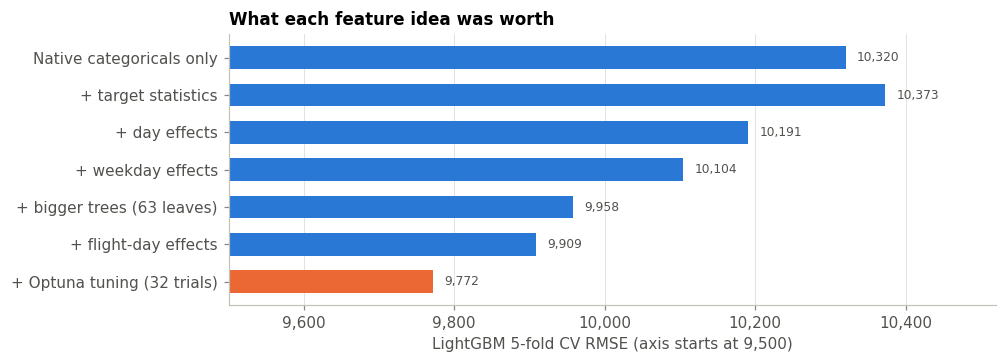

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.2))
yy = np.arange(len(ablation))
ax.barh(yy, ablation["CV RMSE"], height=0.6, color=[BLUE] * (len(ablation) - 1) + [ORANGE])
for i, v in enumerate(ablation["CV RMSE"]):
    ax.text(v + 15, i, f"{v:,.0f}", va="center", color=INK2, fontsize=8)
ax.set_yticks(yy, ablation["step"])
ax.invert_yaxis()
ax.set_xlim(9500, 10520)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("LightGBM 5-fold CV RMSE (axis starts at 9,500)")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_title("What each feature idea was worth")
plt.show()

The travel-date features (day, weekday and flight-day effects) gave the largest gains, about 320 RMSE in total; plain target statistics on their own did not help. Kernel-smoothed day effects were also tried and rejected (CV 9,982).

Next: **03_Models**.